# moonshot_ml_sandbox — conditional-probability investigation (Fork 3)

**The question, in probability language.** For each feature, does conditioning on
it reshape the distribution of forward outcomes — and *which moment* of that
distribution? We measure `P(event | feature-decile)` for three events chosen to
probe three different moments:

| Event | Definition (cross-sectional, per date) | Moment probed |
|---|---|---|
| **R** (return) | forward return in top quintile that day | 1st (mean / outperformance) |
| **V** (risk) | forward realized vol in top quintile that day | 2nd (variance / turbulence) |
| **T** (tail) | \|forward return\| in top quintile that day | 4th (tail magnitude) |

**One machinery, three events, three moments.** Only the counted event changes.

**Why every number is trustworthy (the rigor, made explicit):**
- **Structural null.** Each event is a top-quintile membership, so unconditional
  `P(event) = 0.20` by construction. "No signal" = flat line at 0.20 — arithmetic,
  not an assumption.
- **Point-in-time bins.** Decile boundaries for each date come from a **trailing
  252-day** window of past feature values only — a card's bin is assignable in
  real time, no look-ahead. (Costs the first ~year of data.)
- **Honest uncertainty.** A **block bootstrap** (resample whole date-blocks)
  gives CIs that respect the dependence and fat tails of financial data — where
  textbook formulas would be overconfident.
- **Anti-fishing.** The 5x3 combinations, 10 deciles, 21-day blocks, B=1000 are
  **pre-registered here** — not tuned after seeing results. Intervals are widened
  Bonferroni-style (15 families) so the family-wide false-positive rate stays ~5%.
- **Anti-regime-artifact.** Everything is recomputed on an **early half** and a
  **late half**; a signal is trustworthy only if it appears in both.

**Honest boundary.** This establishes *which features carry reliable, stable
information about which moments*. It does NOT establish payoff magnitude or
net-of-cost tradeability — those are downstream. This is the foundation, not the
strategy.

**Expectation:** R-event signals weak/wide (returns are near-unpredictable);
V- and T-event signals stronger/tighter (risk and tails persist). If so, the test
empirically proves this data's reliable structure lives in risk, not return.

## Cell 0 — Mount, load, and rebuild the forward window quantities

In [1]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
datasets = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))
assert datasets, f"No V1 dataset in {SANDBOX_DIR}."
DATASET_PATH = datasets[-1]
print(f"Loading (READ-ONLY): {DATASET_PATH.name}")

Mounted at /content/drive
Loading (READ-ONLY): ml_sandbox_v1_dataset_2026-09-07.parquet


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet(DATASET_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date","ticker"]).reset_index(drop=True)

RAW = ["momentum_12_1","reversal_1m","realized_vol_60","log_turnover","overnight_drift"]
Z   = [f + "_z" for f in RAW]
NICE = {"momentum_12_1":"Momentum","reversal_1m":"Reversal","realized_vol_60":"Realized vol",
        "log_turnover":"Log-turnover","overnight_drift":"Overnight drift"}

EXPORT_DIR = SANDBOX_DIR / "viz_exports_condprob"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_fig = {"n": 0}
def save_fig(fig, name):
    _fig["n"] += 1
    p = EXPORT_DIR / f"{_fig['n']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"  [saved: {p.name}]")

print(f"{len(df):,} cards | {df['date'].min().date()} -> {df['date'].max().date()}")
print("columns present:", [c for c in df.columns if 'fwd' in c or c in ('Open','Close')])

1,813,407 cards | 2011-01-03 -> 2026-06-10
columns present: ['fwd_ret_20d']


## Cell 1 — Build the three event columns (probe three moments)

- **R** needs the forward RETURN — already in the dataset as `fwd_ret_20d`.
- **T** needs `|forward return|` — just the absolute value of the same column.
- **V** needs forward realized VOLATILITY, which is NOT in the V1 dataset. We must
  reconstruct it from the source panel: the std of each stock's daily returns over
  its own forward window (t+1..t+21), point-in-time consistent with the return
  target. We read the frozen v3 panel READ-ONLY to get daily returns, compute
  forward vol per card, and join it on.

Each event is then top-quintile WITHIN each date. We assert each event's
unconditional mean is ~0.20 (proves the construction).

In [3]:
# R and T come straight from the dataset
df["fwd_abs_ret"] = df["fwd_ret_20d"].abs()

# --- V: reconstruct forward realized vol from the source panel ----------------
COMPOUNDING_FEATURES = Path("/content/drive/MyDrive/moonshot_compounding/features")
panels = sorted(COMPOUNDING_FEATURES.glob("feature_panel_with_pit_v2_*.parquet"))
assert panels, "source panel not found for forward-vol reconstruction"
panel = pd.read_parquet(panels[-1], columns=["Date","ticker","daily_return"])
panel["Date"] = pd.to_datetime(panel["Date"]).dt.tz_localize(None)
panel = panel.sort_values(["ticker","Date"]).reset_index(drop=True)

# forward realized vol over the SAME window the target uses: the 20 trading days
# t+1..t+21. Use each ticker's own trading rows (positional, like the builder).
FWD_ENTRY, FWD_HOLD = 1, 20
def add_forward_vol(g):
    g = g.sort_values("Date").reset_index(drop=True)
    dr = g["daily_return"].to_numpy()
    n = len(g); out = np.full(n, np.nan)
    for i in range(n):
        lo, hi = i + FWD_ENTRY, i + FWD_ENTRY + FWD_HOLD
        if hi <= n:
            w = dr[lo:hi]
            w = w[~np.isnan(w)]
            if len(w) >= 10:            # need enough days for a meaningful std
                out[i] = np.std(w, ddof=1)
    g["fwd_vol"] = out
    return g[["Date","ticker","fwd_vol"]]

print("Reconstructing forward realized vol (per ticker; ~a couple minutes)...")
fv = panel.groupby("ticker", group_keys=False).apply(add_forward_vol)
df = df.merge(fv, left_on=["date","ticker"], right_on=["Date","ticker"], how="left")
df = df.drop(columns=["Date"])
print(f"forward vol merged; non-null on {df['fwd_vol'].notna().mean()*100:.1f}% of cards")

Reconstructing forward realized vol (per ticker; ~a couple minutes)...


/tmp/ipykernel_961/2185329806.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fv = panel.groupby("ticker", group_keys=False).apply(add_forward_vol)


forward vol merged; non-null on 100.0% of cards


In [4]:
# Build the three top-quintile-within-date events
def top_quintile_flag(frame, col):
    return frame.groupby("date")[col].transform(
        lambda s: (s.rank(pct=True) > 0.80).astype(float))

df["event_R"] = top_quintile_flag(df, "fwd_ret_20d")
df["event_T"] = top_quintile_flag(df, "fwd_abs_ret")
# V only where fwd_vol exists; others get NaN and are dropped for V
mask_v = df["fwd_vol"].notna()
df["event_V"] = np.nan
df.loc[mask_v, "event_V"] = top_quintile_flag(df[mask_v], "fwd_vol")

EVENTS = {"R":"event_R", "V":"event_V", "T":"event_T"}
ENAME = {"R":"top-quintile RETURN (1st moment)",
         "V":"top-quintile VOLATILITY (2nd moment)",
         "T":"top-quintile |RETURN| — tail (4th moment)"}

print("Unconditional event rates (must be ~0.20 by construction):")
for k, c in EVENTS.items():
    m = df[c].mean()
    print(f"  event_{k}: {m:.4f}   {'OK' if abs(m-0.20)<0.02 else 'CHECK!'}")
    assert abs(m - 0.20) < 0.03, f"event_{k} not ~0.20 — construction problem"

Unconditional event rates (must be ~0.20 by construction):
  event_R: 0.2009   OK
  event_V: 0.2009   OK
  event_T: 0.2009   OK


## Cell 2 — Trailing-252-day point-in-time decile bins

For each date, the decile edges come from the pooled feature-z values in the
**prior 252 trading days only** — never today or later. A card's bin is therefore
assignable in real time. Cards in the first ~252 trading days have no history and
are dropped (documented cost of point-in-time correctness).

In [5]:
all_dates = np.array(sorted(df["date"].unique()))
date_to_pos = {d: i for i, d in enumerate(all_dates)}
TRAIL, N_BINS = 252, 10

def assign_trailing_deciles(frame, feature, n_bins=N_BINS, trail=TRAIL):
    out = np.full(len(frame), -1, dtype=int)
    vals = frame[feature].to_numpy(); dts = frame["date"].to_numpy()
    grp = {d: g.index.to_numpy() for d, g in frame.groupby("date")}
    for d in all_dates:
        pos = date_to_pos[d]
        if pos < trail: continue
        lo_date = all_dates[pos - trail]
        hist = (dts >= lo_date) & (dts < d)
        if hist.sum() < 2000: continue
        edges = np.quantile(vals[hist], np.linspace(0, 1, n_bins+1))
        edges[0], edges[-1] = -np.inf, np.inf
        idx = grp[d]
        out[idx] = np.clip(np.digitize(vals[idx], edges[1:-1]), 0, n_bins-1)
    return out

for f in RAW:
    df["bin_"+f] = assign_trailing_deciles(df, f+"_z")

kept = df[df["bin_"+RAW[0]] >= 0].copy()   # rows with valid trailing bins
print(f"dropped first {len(df)-len(kept):,} cards (no 252d history); "
      f"kept {len(kept):,} from {kept['date'].min().date()} onward")

# early / late split for stability (on the kept set)
mid = kept["date"].quantile(0.5)
kept["half"] = np.where(kept["date"] <= mid, "early", "late")
print(f"early <= {mid.date()} < late")

dropped first 118,085 cards (no 252d history); kept 1,695,322 from 2012-01-07 onward
early <= 2019-02-21 < late


## Cell 3 — Estimator + block bootstrap + multiplicity-adjusted CIs

`cond_prob`: fraction of cards in each decile where the event fired.
`block_bootstrap_ci`: resample whole 21-day date-blocks (preserving dependence),
recompute, take percentile CIs. We use a Bonferroni-widened confidence level
(15 families) so family-wide false positives stay ~5%.

In [6]:
B_BOOT = 1000
BLOCK = 21
N_FAMILIES = 15                     # 5 features x 3 events (pre-registered)
CONF_RAW = 0.95
CONF_ADJ = 1 - (1 - CONF_RAW)/N_FAMILIES   # ~0.9967 -> family-wide ~95%

def cond_prob(frame, bincol, eventcol, n_bins=N_BINS):
    sub = frame[(frame[bincol] >= 0) & frame[eventcol].notna()]
    return sub.groupby(bincol)[eventcol].mean().reindex(range(n_bins)).to_numpy()

def block_bootstrap_ci(frame, bincol, eventcol, B=B_BOOT, block=BLOCK,
                       conf=CONF_ADJ, seed=0, n_bins=N_BINS):
    rng = np.random.default_rng(seed)
    sub = frame[(frame[bincol] >= 0) & frame[eventcol].notna()]
    d_arr = np.array(sorted(sub["date"].unique()))
    nb = int(np.ceil(len(d_arr)/block))
    blocks = [d_arr[i*block:(i+1)*block] for i in range(nb)]
    by_date = {d: g for d, g in sub.groupby("date")}
    boot = np.full((B, n_bins), np.nan)
    for b in range(B):
        pick = rng.integers(0, len(blocks), size=nb)
        parts = [by_date[d] for bi in pick for d in blocks[bi] if d in by_date]
        rs = pd.concat(parts, ignore_index=True)
        boot[b] = rs.groupby(bincol)[eventcol].mean().reindex(range(n_bins)).to_numpy()
    lo = np.nanpercentile(boot, 100*(1-conf)/2, axis=0)
    hi = np.nanpercentile(boot, 100*(1+conf)/2, axis=0)
    return lo, hi

print(f"Bootstrap config: B={B_BOOT}, block={BLOCK}d, "
      f"adjusted conf={CONF_ADJ:.4f} (family-wide ~{CONF_RAW})")
print("Running 15 families x (full + CI). This is the slow cell — a few minutes.")

Bootstrap config: B=1000, block=21d, adjusted conf=0.9967 (family-wide ~0.95)
Running 15 families x (full + CI). This is the slow cell — a few minutes.


In [7]:
# Run all 15 families: point estimate (full/early/late) + adjusted CI (full)
results = {}
for f in RAW:
    for k, ecol in EVENTS.items():
        key = (f, k)
        p_full  = cond_prob(kept, "bin_"+f, ecol)
        p_early = cond_prob(kept[kept["half"]=="early"], "bin_"+f, ecol)
        p_late  = cond_prob(kept[kept["half"]=="late"],  "bin_"+f, ecol)
        lo, hi  = block_bootstrap_ci(kept, "bin_"+f, ecol)
        results[key] = dict(full=p_full, early=p_early, late=p_late, lo=lo, hi=hi)
    print(f"  done: {NICE[f]}")
print("All 15 families computed.")

  done: Momentum
  done: Reversal
  done: Realized vol
  done: Log-turnover
  done: Overnight drift
All 15 families computed.


## Cell 4 — Charts: one panel per event, all five features, with CIs and null

  [saved: 01_event_R_RETURN.png]


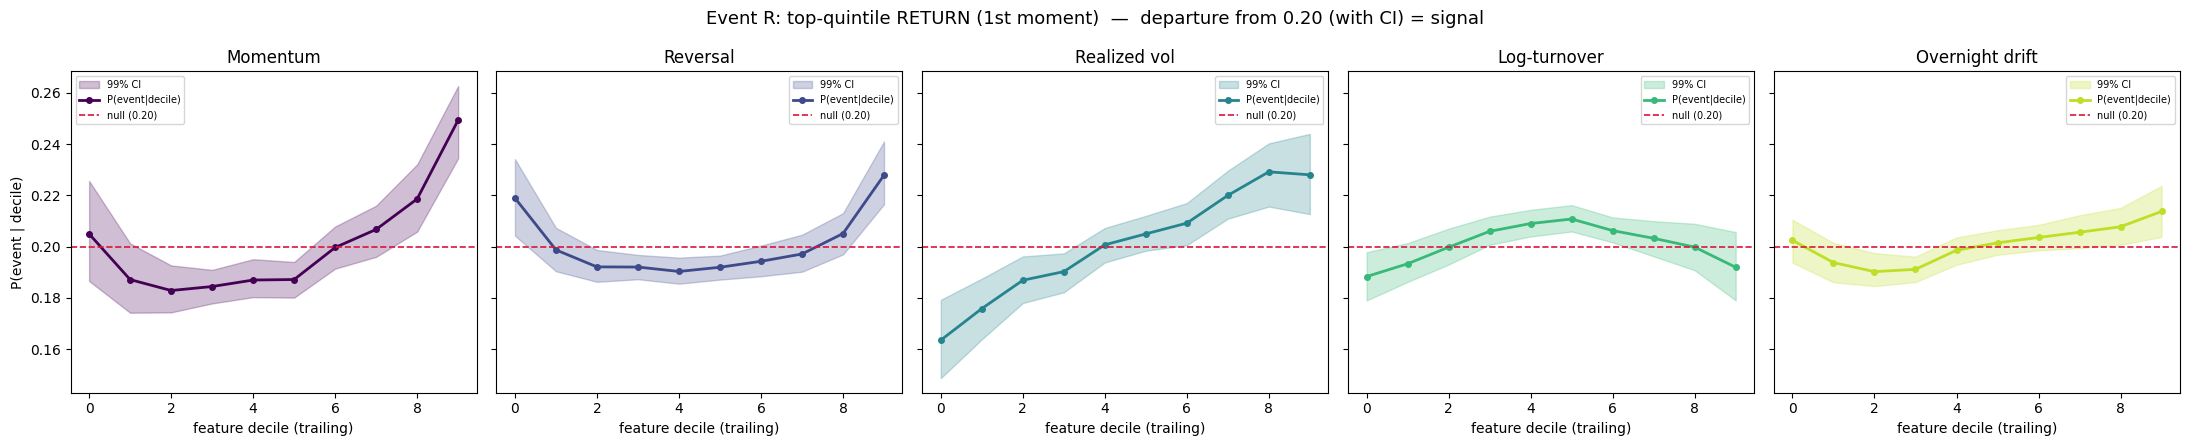

  [saved: 02_event_V_VOLATILITY.png]


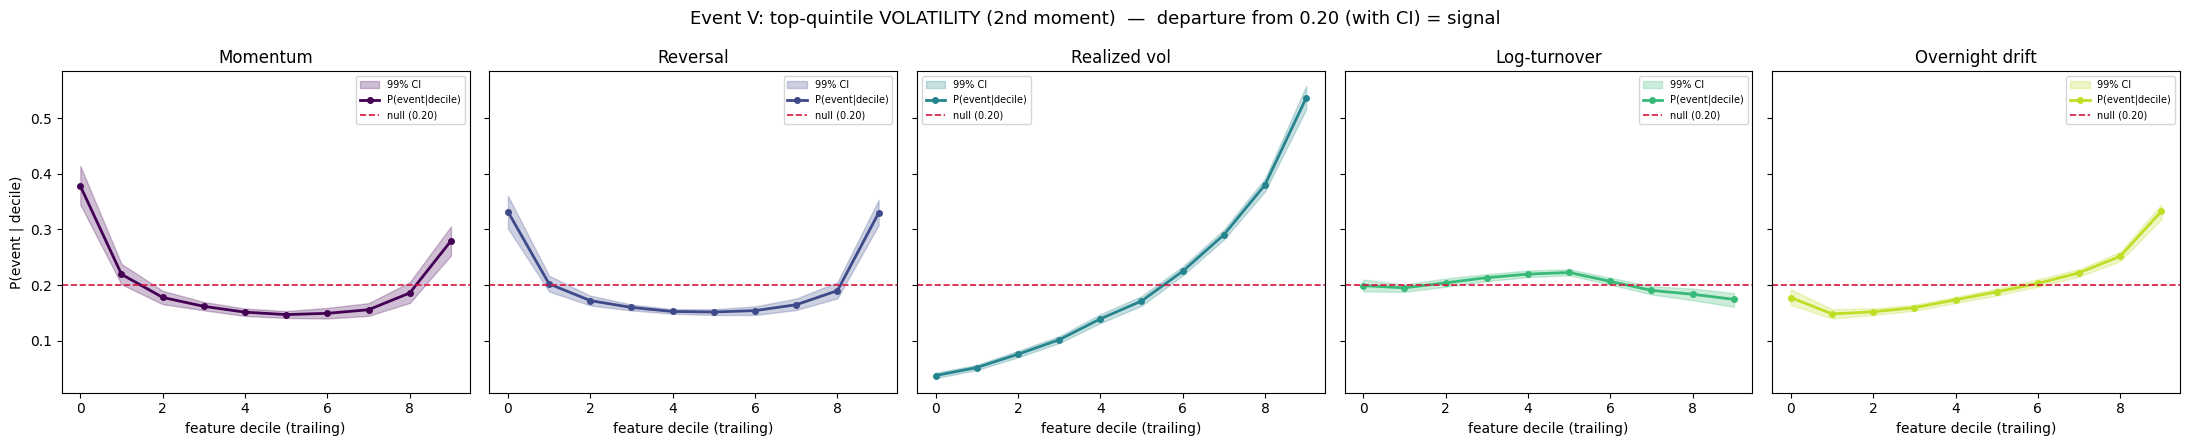

  [saved: 03_event_T_|RETURN|.png]


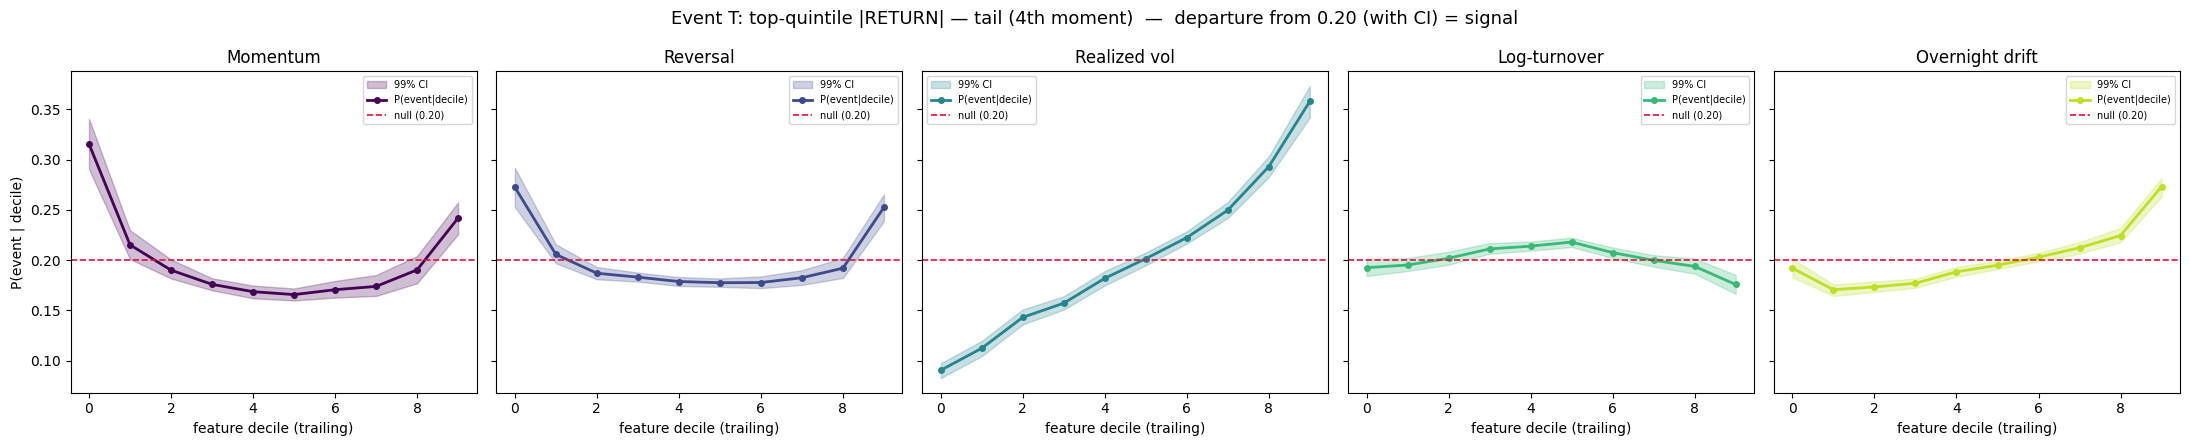

In [8]:
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))

# One figure per event: 5 features, point estimate + adjusted CI band, null@0.20
for k, ecol in EVENTS.items():
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)
    for ax, (fi, f) in zip(axes, enumerate(RAW)):
        r = results[(f, k)]
        x = np.arange(N_BINS)
        ax.fill_between(x, r["lo"], r["hi"], color=colors[fi], alpha=0.25,
                        label=f"{int(CONF_ADJ*100)}% CI")
        ax.plot(x, r["full"], "o-", color=colors[fi], lw=2, ms=4, label="P(event|decile)")
        ax.axhline(0.20, color="crimson", ls="--", lw=1.2, label="null (0.20)")
        ax.set_title(NICE[f]); ax.set_xlabel("feature decile (trailing)")
        if fi == 0: ax.set_ylabel("P(event | decile)")
        ax.legend(fontsize=7)
    fig.suptitle(f"Event {k}: {ENAME[k]}  —  departure from 0.20 (with CI) = signal",
                 fontsize=13)
    fig.tight_layout(); save_fig(fig, f"event_{k}_{ENAME[k].split()[1]}"); plt.show()

  [saved: 04_event_R_stability.png]


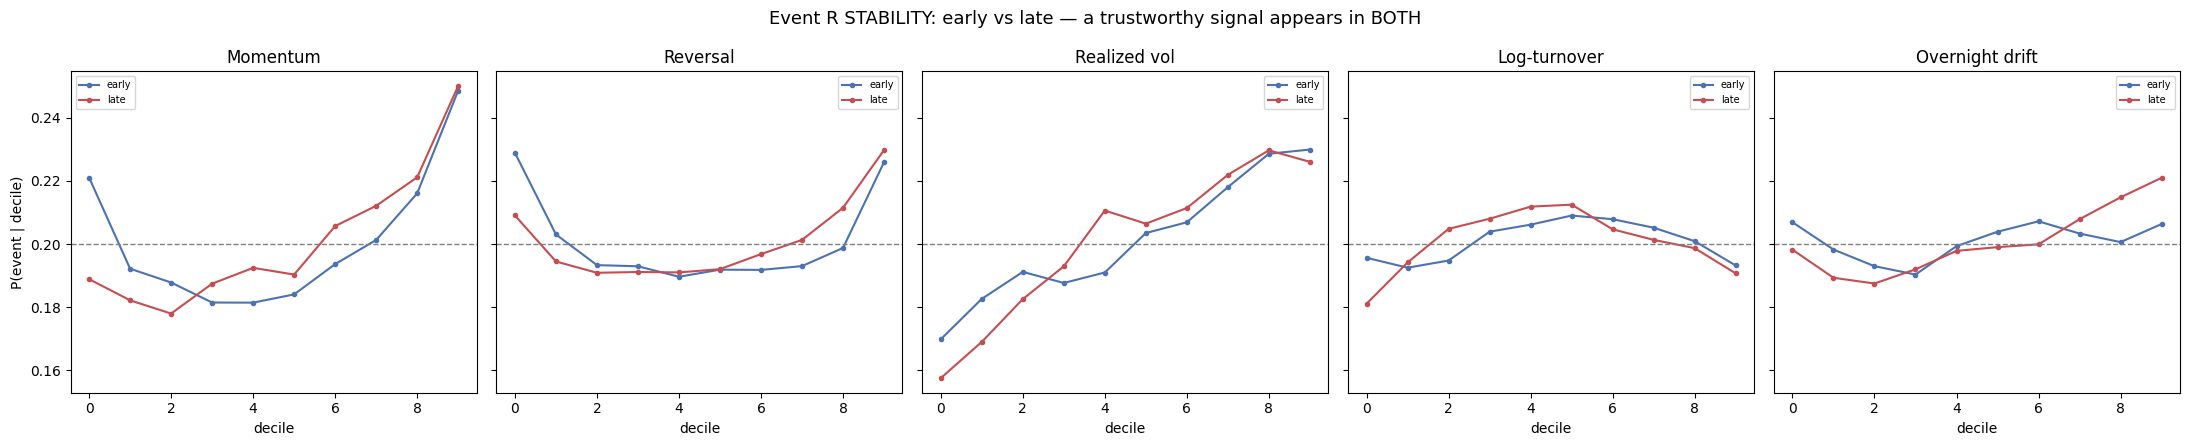

  [saved: 05_event_V_stability.png]


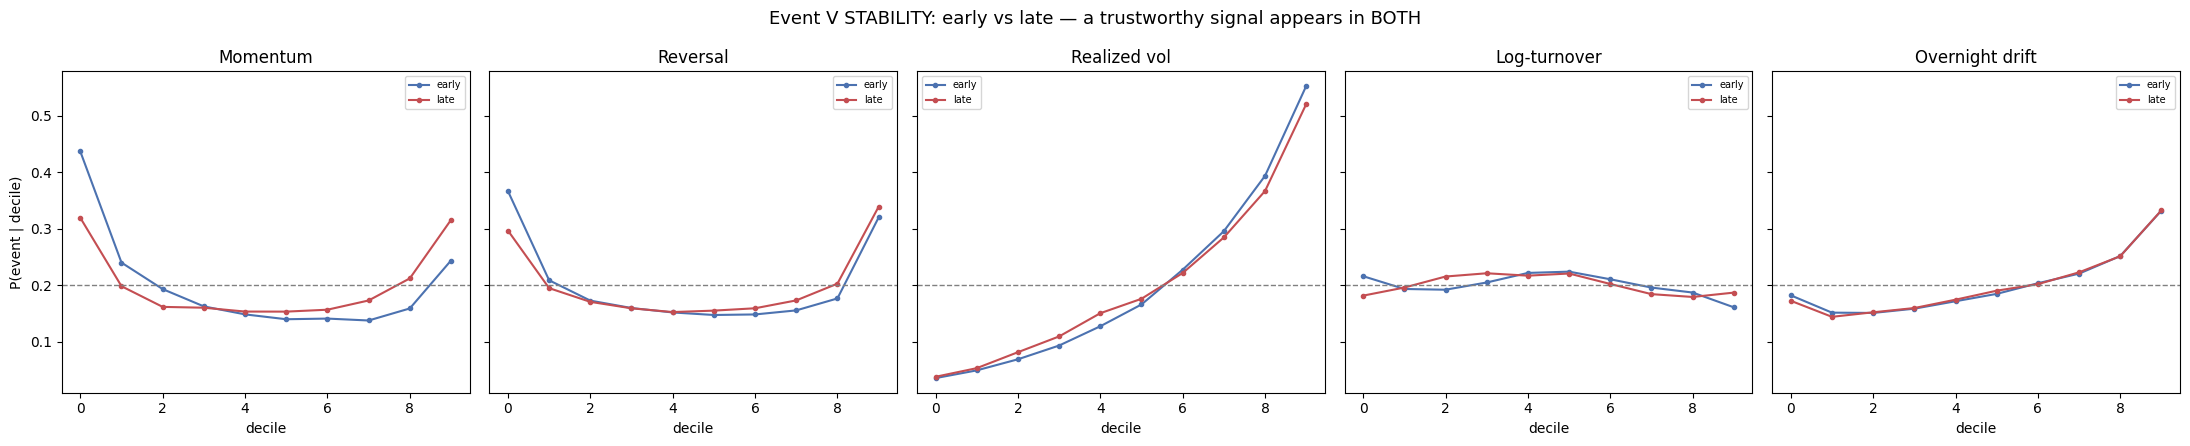

  [saved: 06_event_T_stability.png]


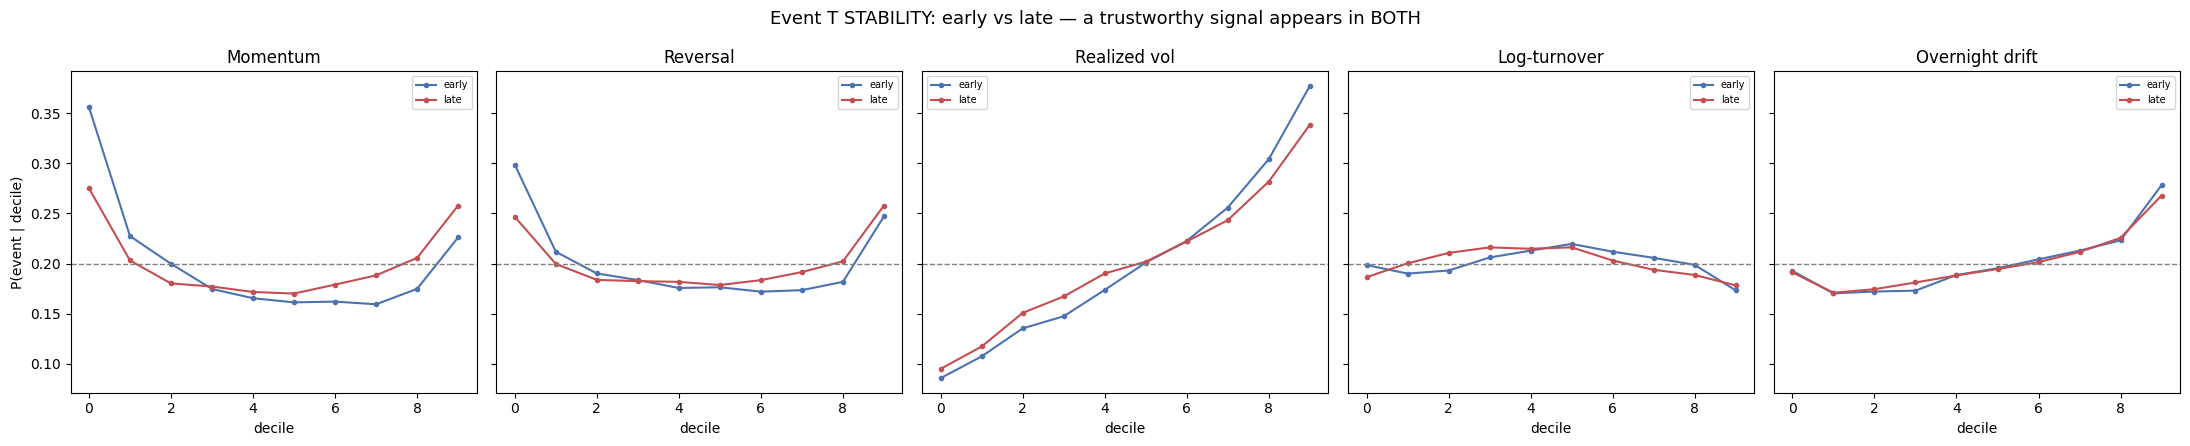

In [9]:
# Stability: early vs late overlay, one panel per event (all features thin lines)
for k, ecol in EVENTS.items():
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)
    for ax, (fi, f) in zip(axes, enumerate(RAW)):
        r = results[(f, k)]; x = np.arange(N_BINS)
        ax.plot(x, r["early"], "o-", color="#4C72B0", lw=1.5, ms=3, label="early")
        ax.plot(x, r["late"],  "o-", color="#C44E52", lw=1.5, ms=3, label="late")
        ax.axhline(0.20, color="grey", ls="--", lw=1)
        ax.set_title(NICE[f]); ax.set_xlabel("decile")
        if fi == 0: ax.set_ylabel("P(event | decile)")
        ax.legend(fontsize=7)
    fig.suptitle(f"Event {k} STABILITY: early vs late — a trustworthy signal "
                 f"appears in BOTH", fontsize=13)
    fig.tight_layout(); save_fig(fig, f"event_{k}_stability"); plt.show()

## Cell 5 — Summary table: signal strength, significance, stability

In [10]:
# For each family, summarise: top-minus-bottom decile gap, whether the extreme
# deciles' adjusted CIs exclude 0.20, and whether early/late agree in sign.
def summarize(f, k):
    r = results[(f, k)]
    gap = r["full"][-1] - r["full"][0]                 # top-bottom decile spread
    # significance: does either extreme decile's adjusted CI exclude 0.20?
    sig_top = (r["lo"][-1] > 0.20) or (r["hi"][-1] < 0.20)
    sig_bot = (r["lo"][0] > 0.20) or (r["hi"][0] < 0.20)
    # stability: same sign of (top-bottom) gap in early and late?
    gap_e = r["early"][-1] - r["early"][0]
    gap_l = r["late"][-1] - r["late"][0]
    stable = np.sign(gap_e) == np.sign(gap_l) and abs(gap_e) > 0.01 and abs(gap_l) > 0.01
    return gap, (sig_top or sig_bot), stable

rows = []
for f in RAW:
    for k in EVENTS:
        gap, sig, stable = summarize(f, k)
        rows.append({"feature":NICE[f], "event":k, "top_minus_bottom":gap,
                     "CI_excludes_null":sig, "early_late_stable":stable,
                     "TRUSTWORTHY": bool(sig and stable)})
summary = pd.DataFrame(rows)
print("="*78)
print("SUMMARY — signal per feature x event")
print("="*78)
print(summary.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print("\nTRUSTWORTHY = CI excludes 0.20 (adjusted) AND early/late agree in sign.")
print("Read the CONTRAST across events R/V/T: which moment carries reliable signal?")

SUMMARY — signal per feature x event
        feature event  top_minus_bottom  CI_excludes_null  early_late_stable  TRUSTWORTHY
       Momentum     R           +0.0444              True               True         True
       Momentum     V           -0.0987              True              False        False
       Momentum     T           -0.0738              True               True         True
       Reversal     R           +0.0089              True              False        False
       Reversal     V           -0.0022              True              False        False
       Reversal     T           -0.0200              True              False        False
   Realized vol     R           +0.0644              True               True         True
   Realized vol     V           +0.4993              True               True         True
   Realized vol     T           +0.2674              True               True         True
   Log-turnover     R           +0.0036              True      

In [11]:
print("="*70); print("SAVED FIGURES:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.glob("*.png")): print("   ", p.name)
print("="*70); print("COPY BELOW THIS LINE AND PASTE BACK"); print("="*70)
print("\n[event unconditional rates]")
for k,c in EVENTS.items(): print(f"  event_{k}: {df[c].mean():.4f}")
print("\n[full-sample P(event|decile), per family]")
for f in RAW:
    for k in EVENTS:
        print(f"  {NICE[f]:<14} {k}: {np.round(results[(f,k)]['full'],3)}")
print("\n[summary table]")
print(summary.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print("="*70)

SAVED FIGURES: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_condprob
    01_event_R_RETURN.png
    02_event_V_VOLATILITY.png
    03_event_T_|RETURN|.png
    04_event_R_stability.png
    05_event_V_stability.png
    06_event_T_stability.png
COPY BELOW THIS LINE AND PASTE BACK

[event unconditional rates]
  event_R: 0.2009
  event_V: 0.2009
  event_T: 0.2009

[full-sample P(event|decile), per family]
  Momentum       R: [0.205 0.187 0.183 0.184 0.187 0.187 0.2   0.207 0.219 0.249]
  Momentum       V: [0.378 0.219 0.178 0.162 0.151 0.147 0.149 0.156 0.186 0.28 ]
  Momentum       T: [0.316 0.215 0.19  0.176 0.169 0.166 0.17  0.174 0.19  0.242]
  Reversal       R: [0.219 0.199 0.192 0.192 0.19  0.192 0.194 0.197 0.205 0.228]
  Reversal       V: [0.332 0.202 0.172 0.16  0.153 0.152 0.154 0.165 0.19  0.33 ]
  Reversal       T: [0.272 0.206 0.187 0.183 0.179 0.177 0.178 0.182 0.192 0.252]
  Realized vol   R: [0.164 0.176 0.187 0.19  0.201 0.205 0.209 0.22  0.229 0.228]
  Realized vol

## How to read the output

1. **Shape vs the red null line.** Flat at 0.20 = no signal. Sloped = monotone
   signal. Hump/U = non-monotone (real dependence correlation would miss).
2. **CI band vs 0.20.** A decile whose adjusted CI excludes 0.20 is a real,
   multiplicity-survived departure.
3. **Early vs late (stability panel).** Trustworthy signal appears in BOTH halves,
   same sign. One-half-only = regime artifact.
4. **The contrast across R / V / T** is the headline: if V and T show strong,
   tight, stable departures while R is weak/flat, the data's reliable structure
   lives in RISK and TAILS, not returns — the thesis of Fork 3, empirically shown.

**Boundary restated:** this shows which features reliably shift the odds of which
kind of outcome. Payoff magnitude and net-of-cost tradeability are downstream.